In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [163]:
df = pd.read_csv("ecommerce_sales_cleaned2.csv")

## 1. Data Understanding

In this section, we will understand the structure, size, data types, and basic statistics of the dataset.

In [164]:
# View first 5 rows
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,city,Product,Category,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode
0,ORD100001,2025-04-13,1358,Customer_1358,South,Hyderabad,Smartphone,Electronics,3,28000,0.05,79800,6800.38,Debit Card
1,ORD100002,2026-03-12,3402,Customer_3402,North,Chandigarh,Smartwatch,Electronics,2,5500,0.00,11000,1224.75,Cash on Delivery
2,ORD100003,2025-09-28,2275,Customer_2275,West,Ahmedabad,Shoes,Fashion,1,3200,0.00,3200,998.30,Credit Card
3,ORD100004,2025-04-17,1376,Customer_1376,Central,Indore,T-Shirt,Fashion,2,900,0.10,1620,418.97,Net Banking
4,ORD100005,2025-03-13,1989,Customer_1989,South,Hyderabad,Coffee Maker,Home Appliances,3,6500,0.10,17550,2156.03,UPI


In [165]:
# Check number of rows and columns
df.shape

(10000, 14)

In [166]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       10000 non-null  object 
 1   Order_Date     10000 non-null  object 
 2   Customer_ID    10000 non-null  int64  
 3   Customer_Name  10000 non-null  object 
 4   Region         10000 non-null  object 
 5   city           10000 non-null  object 
 6   Product        10000 non-null  object 
 7   Category       10000 non-null  object 
 8   Quantity       10000 non-null  int64  
 9   Unit_Price     10000 non-null  int64  
 10  Discount       10000 non-null  float64
 11  Sales          10000 non-null  int64  
 12  Profit         10000 non-null  float64
 13  Payment_Mode   10000 non-null  object 
dtypes: float64(2), int64(4), object(8)
memory usage: 1.1+ MB


In [167]:
# Summary statistics
df.describe()

,Customer_ID,Quantity,Unit_Price,Discount,Sales,Profit
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2249.637100,1.916000,10779.230000,0.099775,18345.618000,1560.487369
std,725.077544,1.111876,16708.851552,0.071461,34260.754765,2613.257870
min,1001.000000,1.000000,900.000000,0.000000,675.000000,-5316.560000
25%,1615.000000,1.000000,2500.000000,0.050000,2800.000000,351.312500
50%,2254.500000,2.000000,4200.000000,0.100000,6080.000000,768.030000
75%,2884.000000,2.000000,8500.000000,0.150000,16150.000000,1729.157500
max,3500.000000,5.000000,65000.000000,0.250000,325000.000000,44323.700000


## 2. Data Quality Check

In this section, we will check the dataset for missing values and duplicate records.

In [168]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Region,0
city,0
Product,0
Category,0
Quantity,0
Unit_Price,0


In [169]:
df.duplicated().sum()


np.int64(0)

## 3. Data Preparation

In this section, we will convert the order date into a proper date format and create Year and Month columns for time-based analysis.

In [170]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       10000 non-null  object        
 1   Order_Date     10000 non-null  datetime64[ns]
 2   Customer_ID    10000 non-null  int64         
 3   Customer_Name  10000 non-null  object        
 4   Region         10000 non-null  object        
 5   city           10000 non-null  object        
 6   Product        10000 non-null  object        
 7   Category       10000 non-null  object        
 8   Quantity       10000 non-null  int64         
 9   Unit_Price     10000 non-null  int64         
 10  Discount       10000 non-null  float64       
 11  Sales          10000 non-null  int64         
 12  Profit         10000 non-null  float64       
 13  Payment_Mode   10000 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(4), object(7)
memory usage: 1.1

In [172]:
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month

df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,city,Product,Category,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Year,Month
0,ORD100001,2025-04-13,1358,Customer_1358,South,Hyderabad,Smartphone,Electronics,3,28000,0.05,79800,6800.38,Debit Card,2025,4
1,ORD100002,2026-03-12,3402,Customer_3402,North,Chandigarh,Smartwatch,Electronics,2,5500,0.00,11000,1224.75,Cash on Delivery,2026,3
2,ORD100003,2025-09-28,2275,Customer_2275,West,Ahmedabad,Shoes,Fashion,1,3200,0.00,3200,998.30,Credit Card,2025,9
3,ORD100004,2025-04-17,1376,Customer_1376,Central,Indore,T-Shirt,Fashion,2,900,0.10,1620,418.97,Net Banking,2025,4
4,ORD100005,2025-03-13,1989,Customer_1989,South,Hyderabad,Coffee Maker,Home Appliances,3,6500,0.10,17550,2156.03,UPI,2025,3


## 4. KPI Analysis

In this section, we will calculate the key performance indicators (KPIs) of the e-commerce business.

In [173]:
# Calculate key business KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
average_order_value = df["Sales"].mean()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", average_order_value)
print("Profit Margin:", profit_margin)

Total Sales: 183456180
Total Profit: 15604873.690000001
Total Orders: 10000
Total Customers: 2450
Average Order Value: 18345.618
Profit Margin: 8.50604961359165


## 5. Product Analysis

In this section, we will analyze product-level sales and profit performance to identify the top and low-performing products.

In [174]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)

Total Sales: 183456180
Total Profit: 15604873.690000001


In [308]:
product_analysis = df.groupby("Product")[["Sales", "Profit"]].sum()

product_analysis["Profit_Margin"] = (
    product_analysis["Profit"] / product_analysis["Sales"]
) * 100

product_analysis.sort_values("Profit_Margin", ascending=False)

,Sales,Profit,Profit_Margin
Product,,,
Shoes,5419360,1400567.94,25.843789
T-Shirt,1736460,446485.62,25.712405
Jacket,2850260,731802.55,25.674940
Backpack,3122820,651258.07,20.854807
Office Chair,10515775,1449325.44,13.782393
Desk,10365600,1408639.77,13.589563
Mixer Grinder,4480980,528210.82,11.787841
Coffee Maker,8176350,953842.98,11.665878
Laptop,75598250,4513163.72,5.969931


In [309]:
product_analysis.sort_values(
    "Profit_Margin",
    ascending=False
).head(3)

,Sales,Profit,Profit_Margin
Product,,,
Shoes,5419360,1400567.94,25.843789
T-Shirt,1736460,446485.62,25.712405
Jacket,2850260,731802.55,25.674940


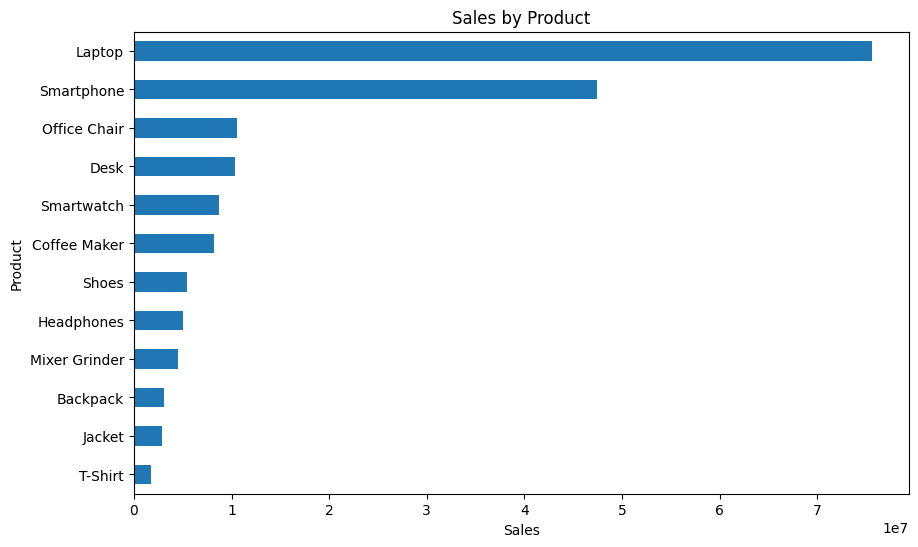

In [310]:
product_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Sales by Product")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.show()

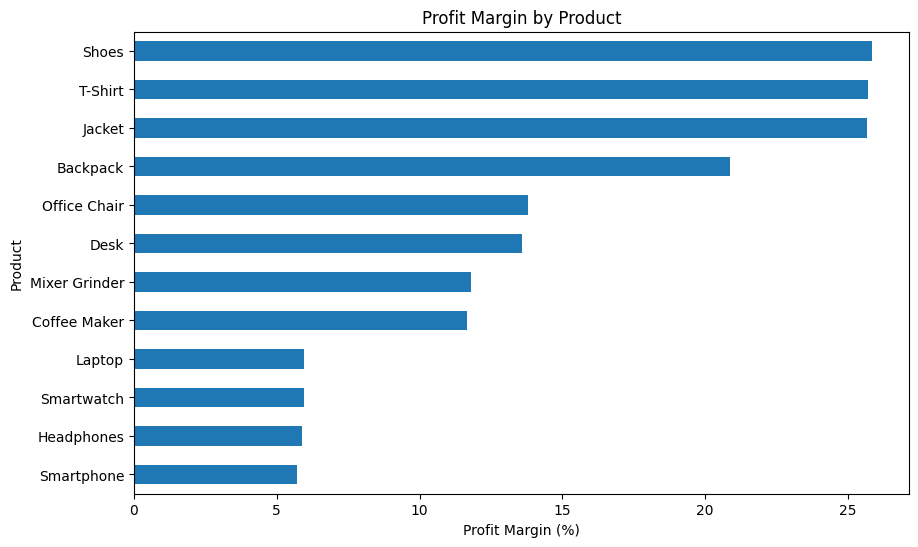

In [311]:
product_analysis["Profit_Margin"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Profit Margin by Product")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product")
plt.show()

In [175]:
product_sales = df.groupby("Product")["Sales"].sum()

print(product_sales)

Product
Backpack          3122820
Coffee Maker      8176350
Desk             10365600
Headphones        5029500
Jacket            2850260
Laptop           75598250
Mixer Grinder     4480980
Office Chair     10515775
Shoes             5419360
Smartphone       47419400
Smartwatch        8741425
T-Shirt           1736460
Name: Sales, dtype: int64


In [176]:
product_sales.sort_values(ascending=False)

,Sales
Product,
Laptop,75598250
Smartphone,47419400
Office Chair,10515775
Desk,10365600
Smartwatch,8741425
Coffee Maker,8176350
Shoes,5419360
Headphones,5029500
Mixer Grinder,4480980


In [177]:
top_3_products = product_sales.sort_values(ascending=False).head(3)

print(top_3_products)

Product
Laptop          75598250
Smartphone      47419400
Office Chair    10515775
Name: Sales, dtype: int64


## 6. Category Analysis

In this section, we will analyze sales and profit performance across different product categories.

In [178]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Accessories          3122820
Electronics        136788575
Fashion             10006080
Furniture           20881375
Home Appliances     12657330
Name: Sales, dtype: int64


In [179]:
highest_category = category_sales.idxmax()

print("Highest Sales Category:", highest_category)

Highest Sales Category: Electronics


In [180]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

Category
Accessories         651258.07
Electronics        8034740.50
Fashion            2578856.11
Furniture          2857965.21
Home Appliances    1482053.80
Name: Profit, dtype: float64


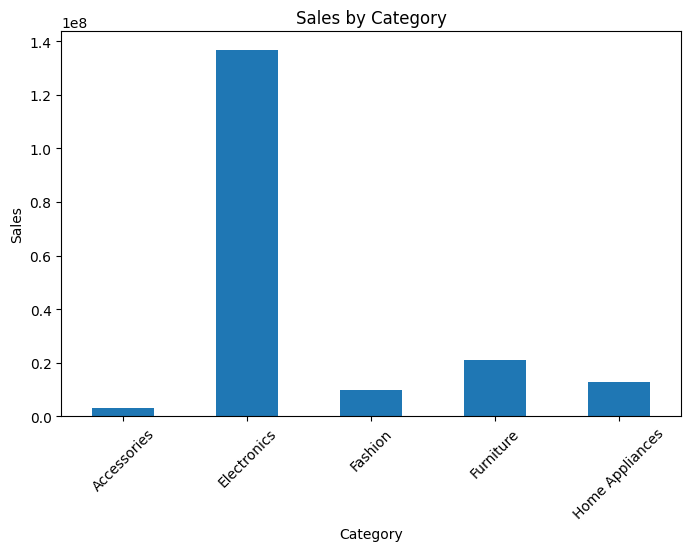

In [313]:
category_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

In [181]:
highest_profit_category = category_profit.idxmax()

print("Highest Profit Category:", highest_profit_category)

Highest Profit Category: Electronics


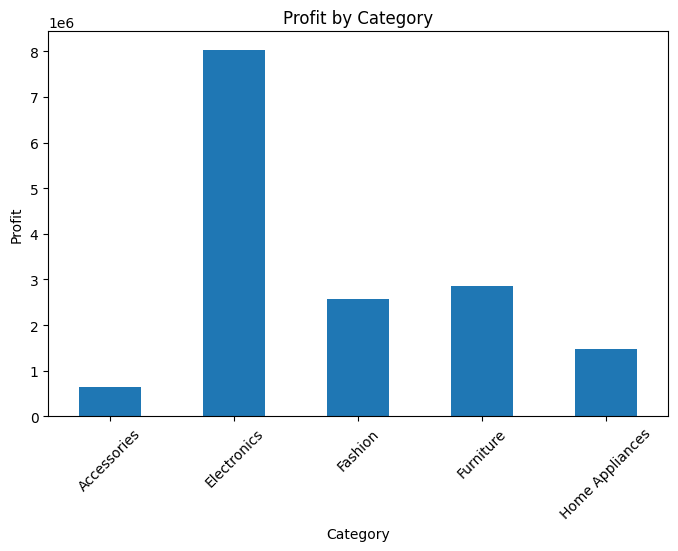

In [315]:
category_profit.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

In [182]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales)

Region
Central    26472575
East       28199995
North      34465345
South      42373765
West       51944500
Name: Sales, dtype: int64


In [183]:
highest_sales_region = region_sales.idxmax()

print("Highest Sales Region:", highest_sales_region)

Highest Sales Region: West


In [184]:
lowest_sales_region = region_sales.idxmin()

print("Lowest Sales Region:", lowest_sales_region)

Lowest Sales Region: Central


In [185]:
monthly_sales = df.groupby(["Year", "Month"])["Sales"].sum()

print(monthly_sales)

Year  Month
2025  1        10528830
      2         9381670
      3        10172635
      4        10791815
      5        10003200
      6         9932095
      7         9682640
      8        10761300
      9        10248785
      10        9313150
      11       10140400
      12       10766540
2026  1        11735110
      2         7976940
      3        10949220
      4         9388465
      5        11293215
      6        10390170
Name: Sales, dtype: int64


In [186]:
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

print("Highest Sales Month:", highest_month)
print("Highest Sales:", highest_sales)

Highest Sales Month: (np.int32(2026), np.int32(1))
Highest Sales: 11735110


In [187]:
lowest_month = monthly_sales.idxmin()
lowest_sales = monthly_sales.min()

print("Lowest Sales Month:", lowest_month)
print("Lowest Sales:", lowest_sales)

Lowest Sales Month: (np.int32(2026), np.int32(2))
Lowest Sales: 7976940


In [188]:
product_profit = df.groupby("Product")["Profit"].sum()

print(product_profit)

Product
Backpack          651258.07
Coffee Maker      953842.98
Desk             1408639.77
Headphones        296874.67
Jacket            731802.55
Laptop           4513163.72
Mixer Grinder     528210.82
Office Chair     1449325.44
Shoes            1400567.94
Smartphone       2705096.83
Smartwatch        519605.28
T-Shirt           446485.62
Name: Profit, dtype: float64


In [189]:
highest_profit_product = product_profit.idxmax()
highest_profit = product_profit.max()

print("Highest Profit Product:", highest_profit_product)
print("Highest Profit:", highest_profit)

Highest Profit Product: Laptop
Highest Profit: 4513163.72


In [190]:
lowest_profit_product = product_profit.idxmin()
lowest_profit = product_profit.min()

print("Lowest Profit Product:", lowest_profit_product)
print("Lowest Profit:", lowest_profit)

Lowest Profit Product: Headphones
Lowest Profit: 296874.67


In [191]:
loss_orders = df[df["Profit"] < 0]

print(loss_orders.shape)

(249, 16)


In [192]:
loss_by_product = loss_orders.groupby("Product")["Order_ID"].count()

print(loss_by_product.sort_values(ascending=False))

Product
Smartphone    72
Headphones    71
Smartwatch    56
Laptop        50
Name: Order_ID, dtype: int64


In [193]:
top_3_loss_products = loss_by_product.sort_values(ascending=False).head(3)

print(top_3_loss_products)

Product
Smartphone    72
Headphones    71
Smartwatch    56
Name: Order_ID, dtype: int64


In [194]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum()

print(customer_sales)

Customer_ID
1001     96400
1002      3350
1003      9340
1004     97590
1005     68790
         ...  
3496    111345
3497     22800
3498    133585
3499     77725
3500     78455
Name: Sales, Length: 2450, dtype: int64


In [195]:
top_10_customers = customer_sales.sort_values(ascending=False).head(10)

print(top_10_customers)

Customer_ID
2324    670625
1784    571675
1551    539500
1460    420175
1277    418930
2980    418600
1412    414870
2977    414640
1992    412060
1606    404935
Name: Sales, dtype: int64


In [196]:
average_order_value = df["Sales"].mean()

print("Average Order Value:", average_order_value)

Average Order Value: 18345.618


In [197]:
region_aov = df.groupby("Region")["Sales"].mean()

print(region_aov)

Region
Central    18244.365955
East       19015.505732
North      17692.682238
South      18899.984389
West       18061.369958
Name: Sales, dtype: float64


In [198]:
highest_aov_region = region_aov.idxmax()
highest_aov = region_aov.max()

print("Highest AOV Region:", highest_aov_region)
print("Highest AOV:", round(highest_aov, 2))

Highest AOV Region: East
Highest AOV: 19015.51


In [199]:
product_analysis = df.groupby("Product")[["Sales", "Profit"]].sum()

print(product_analysis)


                  Sales      Profit
Product                            
Backpack        3122820   651258.07
Coffee Maker    8176350   953842.98
Desk           10365600  1408639.77
Headphones      5029500   296874.67
Jacket          2850260   731802.55
Laptop         75598250  4513163.72
Mixer Grinder   4480980   528210.82
Office Chair   10515775  1449325.44
Shoes           5419360  1400567.94
Smartphone     47419400  2705096.83
Smartwatch      8741425   519605.28
T-Shirt         1736460   446485.62


In [200]:
product_analysis = df.groupby("Product")[["Sales", "Profit"]].sum()

print(product_analysis)

                  Sales      Profit
Product                            
Backpack        3122820   651258.07
Coffee Maker    8176350   953842.98
Desk           10365600  1408639.77
Headphones      5029500   296874.67
Jacket          2850260   731802.55
Laptop         75598250  4513163.72
Mixer Grinder   4480980   528210.82
Office Chair   10515775  1449325.44
Shoes           5419360  1400567.94
Smartphone     47419400  2705096.83
Smartwatch      8741425   519605.28
T-Shirt         1736460   446485.62


In [201]:
product_analysis["Profit_Margin"] = (
    product_analysis["Profit"] / product_analysis["Sales"]
) * 100

print(product_analysis)

                  Sales      Profit  Profit_Margin
Product                                           
Backpack        3122820   651258.07      20.854807
Coffee Maker    8176350   953842.98      11.665878
Desk           10365600  1408639.77      13.589563
Headphones      5029500   296874.67       5.902668
Jacket          2850260   731802.55      25.674940
Laptop         75598250  4513163.72       5.969931
Mixer Grinder   4480980   528210.82      11.787841
Office Chair   10515775  1449325.44      13.782393
Shoes           5419360  1400567.94      25.843789
Smartphone     47419400  2705096.83       5.704621
Smartwatch      8741425   519605.28       5.944171
T-Shirt         1736460   446485.62      25.712405


In [202]:
highest_margin_product = product_analysis["Profit_Margin"].idxmax()
highest_margin = product_analysis["Profit_Margin"].max()

print("Highest Profit Margin Product:", highest_margin_product)
print("Profit Margin:", round(highest_margin, 2), "%")

Highest Profit Margin Product: Shoes
Profit Margin: 25.84 %


In [203]:
low_margin_products = product_analysis[
    product_analysis["Profit_Margin"] < 10
]

print(low_margin_products)

               Sales      Profit  Profit_Margin
Product                                        
Headphones   5029500   296874.67       5.902668
Laptop      75598250  4513163.72       5.969931
Smartphone  47419400  2705096.83       5.704621
Smartwatch   8741425   519605.28       5.944171


In [204]:
top_3_margin_products = product_analysis[
    "Profit_Margin"
].sort_values(ascending=False).head(3)

print(top_3_margin_products)

Product
Shoes      25.843789
T-Shirt    25.712405
Jacket     25.674940
Name: Profit_Margin, dtype: float64


In [205]:
payment_sales = df.groupby("Payment_Mode")["Sales"].sum()

print(payment_sales)

Payment_Mode
Cash on Delivery    18257640
Credit Card         46540205
Credit card            14850
Debit Card          30310795
Net Banking         25041190
UPI                 63288260
upi                     3240
Name: Sales, dtype: int64


In [206]:
df["Payment_Mode"] = df["Payment_Mode"].str.title()

print(df["Payment_Mode"].value_counts())

Payment_Mode
Upi                 3531
Credit Card         2416
Debit Card          1771
Net Banking         1271
Cash On Delivery    1011
Name: count, dtype: int64


In [207]:
payment_sales = df.groupby("Payment_Mode")["Sales"].sum()

print(payment_sales.sort_values(ascending=False))

Payment_Mode
Upi                 63291500
Credit Card         46555055
Debit Card          30310795
Net Banking         25041190
Cash On Delivery    18257640
Name: Sales, dtype: int64


In [208]:
highest_payment_mode = payment_sales.idxmax()
highest_payment_sales = payment_sales.max()

print("Highest Sales Payment Mode:", highest_payment_mode)
print("Sales:", highest_payment_sales)

Highest Sales Payment Mode: Upi
Sales: 63291500


In [209]:
region_profit = df.groupby("Region")["Profit"].sum()

print(region_profit.sort_values(ascending=False))

Region
West       4356342.35
South      3486526.56
North      3101280.57
East       2411463.87
Central    2249260.34
Name: Profit, dtype: float64


In [210]:
most_profitable_region = region_profit.idxmax()
highest_profit = region_profit.max()

print("Most Profitable Region:", most_profitable_region)
print("Profit:", highest_profit)

Most Profitable Region: West
Profit: 4356342.35


In [211]:
product_profit = df.groupby("Product")["Profit"].sum()

print(product_profit.sort_values(ascending=False))

Product
Laptop           4513163.72
Smartphone       2705096.83
Office Chair     1449325.44
Desk             1408639.77
Shoes            1400567.94
Coffee Maker      953842.98
Jacket            731802.55
Backpack          651258.07
Mixer Grinder     528210.82
Smartwatch        519605.28
T-Shirt           446485.62
Headphones        296874.67
Name: Profit, dtype: float64


In [212]:
most_profitable_product = product_profit.idxmax()
highest_product_profit = product_profit.max()

print("Most Profitable Product:", most_profitable_product)
print("Profit:", highest_product_profit)

Most Profitable Product: Laptop
Profit: 4513163.72


In [213]:
least_profitable_product = product_profit.idxmin()
lowest_product_profit = product_profit.min()

print("Least Profitable Product:", least_profitable_product)
print("Profit:", lowest_product_profit)

Least Profitable Product: Headphones
Profit: 296874.67


In [214]:
top_5_profitable_products = product_profit.sort_values(ascending=False).head(5)

print(top_5_profitable_products)

Product
Laptop          4513163.72
Smartphone      2705096.83
Office Chair    1449325.44
Desk            1408639.77
Shoes           1400567.94
Name: Profit, dtype: float64


In [215]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum()

top_5_customers = customer_sales.sort_values(ascending=False).head(5)

print(top_5_customers)

Customer_ID
2324    670625
1784    571675
1551    539500
1460    420175
1277    418930
Name: Sales, dtype: int64


In [216]:
customer_profit = df.groupby("Customer_ID")["Profit"].sum()

top_5_profit_customers = customer_profit.sort_values(ascending=False).head(5)

print(top_5_profit_customers)

Customer_ID
1992    54608.24
2324    50982.77
1784    46418.42
2173    45206.05
2390    42863.64
Name: Profit, dtype: float64


In [217]:
customer_orders = df.groupby("Customer_ID")["Order_ID"].count()

customers_more_than_5 = customer_orders[customer_orders > 5]

print(customers_more_than_5)

Customer_ID
1001    7
1005    6
1006    6
1007    6
1009    8
       ..
3474    6
3476    6
3485    6
3489    6
3500    6
Name: Order_ID, Length: 530, dtype: int64


In [218]:
top_5_order_customers = customer_orders.sort_values(ascending=False).head(5)

print(top_5_order_customers)

Customer_ID
1596    12
2579    12
3238    11
2134    11
2287    11
Name: Order_ID, dtype: int64


In [219]:
average_customer_sales = customer_sales.mean()

print("Average Sales per Customer:", average_customer_sales)

Average Sales per Customer: 74880.07346938776


In [220]:
customer_aov = df.groupby("Customer_ID")["Sales"].mean()

top_5_customer_aov = customer_aov.sort_values(ascending=False).head(5)

print(top_5_customer_aov)

Customer_ID
1551    269750.0
2336    221000.0
2717    195000.0
2159    175500.0
2997    175500.0
Name: Sales, dtype: float64


In [221]:
unique_customers = df["Customer_ID"].nunique()

print("Unique Customers:", unique_customers)

Unique Customers: 2450


In [222]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales.sort_values(ascending=False))

Category
Electronics        136788575
Furniture           20881375
Home Appliances     12657330
Fashion             10006080
Accessories          3122820
Name: Sales, dtype: int64


In [223]:
highest_sales_category = category_sales.idxmax()
lowest_sales_category = category_sales.idxmin()

print("Highest Sales Category:", highest_sales_category)
print("Lowest Sales Category:", lowest_sales_category)

Highest Sales Category: Electronics
Lowest Sales Category: Accessories


In [224]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit.sort_values(ascending=False))

Category
Electronics        8034740.50
Furniture          2857965.21
Fashion            2578856.11
Home Appliances    1482053.80
Accessories         651258.07
Name: Profit, dtype: float64


In [225]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()

category_analysis

,Sales,Profit
Category,,
Accessories,3122820,651258.07
Electronics,136788575,8034740.50
Fashion,10006080,2578856.11
Furniture,20881375,2857965.21
Home Appliances,12657330,1482053.80


In [226]:
category_analysis["Profit_Margin"] = (
    category_analysis["Profit"] / category_analysis["Sales"]
) * 100

print(category_analysis)


                     Sales      Profit  Profit_Margin
Category                                             
Accessories        3122820   651258.07      20.854807
Electronics      136788575  8034740.50       5.873839
Fashion           10006080  2578856.11      25.772891
Furniture         20881375  2857965.21      13.686672
Home Appliances   12657330  1482053.80      11.709056


In [227]:
highest_margin_category = category_analysis["Profit_Margin"].idxmax()
highest_margin = category_analysis["Profit_Margin"].max()

print("Highest Margin Category:", highest_margin_category)
print("Profit Margin:", highest_margin)

Highest Margin Category: Fashion
Profit Margin: 25.772891182161246


In [228]:
lowest_margin_category = category_analysis["Profit_Margin"].idxmin()
lowest_margin = category_analysis["Profit_Margin"].min()

print("Lowest Margin Category:", lowest_margin_category)
print("Profit Margin:", lowest_margin)

Lowest Margin Category: Electronics
Profit Margin: 5.873838878722145


In [229]:
low_margin_products = product_analysis[
    product_analysis["Profit_Margin"] < 10
]

print(low_margin_products)

               Sales      Profit  Profit_Margin
Product                                        
Headphones   5029500   296874.67       5.902668
Laptop      75598250  4513163.72       5.969931
Smartphone  47419400  2705096.83       5.704621
Smartwatch   8741425   519605.28       5.944171


In [230]:
highest_margin_product = product_analysis["Profit_Margin"].idxmax()
highest_product_margin = product_analysis["Profit_Margin"].max()

print("Highest Margin Product:", highest_margin_product)
print("Profit Margin:", highest_product_margin)

Highest Margin Product: Shoes
Profit Margin: 25.843788565439464


In [231]:
top_3_margin_products = (
    product_analysis["Profit_Margin"]
    .sort_values(ascending=False)
    .head(3)
)

print(top_3_margin_products)

Product
Shoes      25.843789
T-Shirt    25.712405
Jacket     25.674940
Name: Profit_Margin, dtype: float64


In [232]:
loss_orders = df[df["Profit"] < 0]

loss_by_product = loss_orders.groupby("Product")["Order_ID"].count()

print(loss_by_product.sort_values(ascending=False))

Product
Smartphone    72
Headphones    71
Smartwatch    56
Laptop        50
Name: Order_ID, dtype: int64


In [233]:
total_loss_orders = (df["Profit"] < 0).sum()

print("Total Loss-Making Orders:", total_loss_orders)

Total Loss-Making Orders: 249


## 7. Regional Analysis

In this section, we will analyze sales and profit performance across different regions.


In [234]:
loss_by_region = (
    loss_orders.groupby("Region")["Order_ID"].count()
)

print(loss_by_region.sort_values(ascending=False))

Region
West       81
South      53
North      44
Central    37
East       34
Name: Order_ID, dtype: int64


In [235]:
region_avg_profit = df.groupby("Region")["Profit"].mean()

print(region_avg_profit.sort_values(ascending=False))

Region
East       1626.071389
North      1592.033147
South      1555.096592
Central    1550.144962
West       1514.722653
Name: Profit, dtype: float64


In [236]:
region_analysis = df.groupby("Region")[["Sales", "Profit"]].sum()

print(region_analysis)

            Sales      Profit
Region                       
Central  26472575  2249260.34
East     28199995  2411463.87
North    34465345  3101280.57
South    42373765  3486526.56
West     51944500  4356342.35


In [237]:
region_analysis["Profit_Margin"] = (
    region_analysis["Profit"] / region_analysis["Sales"]
) * 100

print(region_analysis)

            Sales      Profit  Profit_Margin
Region                                      
Central  26472575  2249260.34       8.496568
East     28199995  2411463.87       8.551292
North    34465345  3101280.57       8.998258
South    42373765  3486526.56       8.228031
West     51944500  4356342.35       8.386532


In [238]:
top_3_margin_regions = (
    region_analysis["Profit_Margin"]
    .sort_values(ascending=False)
    .head(3)
)

print(top_3_margin_regions)

Region
North      8.998258
East       8.551292
Central    8.496568
Name: Profit_Margin, dtype: float64


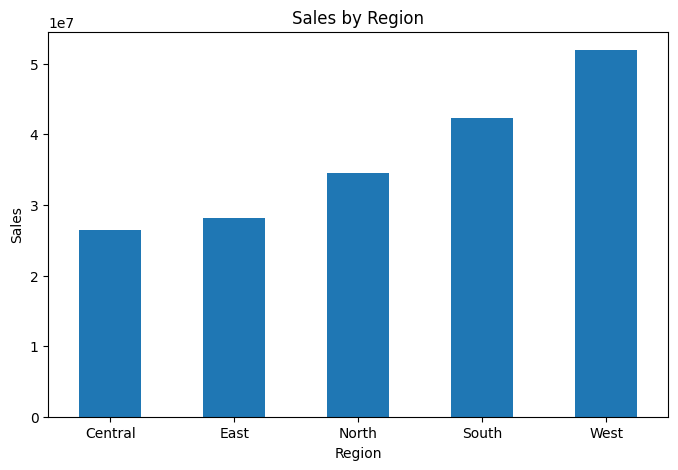

In [316]:
region_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

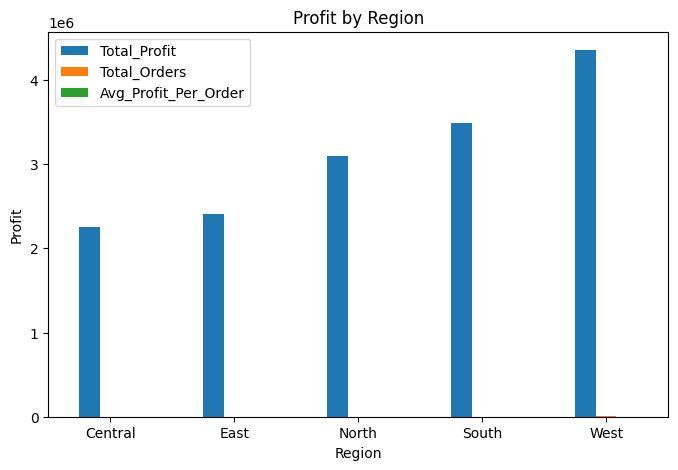

In [317]:
region_profit.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.show()

In [239]:
product_quantity = df.groupby("Product")["Quantity"].sum()

top_3_quantity_products = (
    product_quantity
    .sort_values(ascending=False)
    .head(3)
)

print(top_3_quantity_products)


Product
Headphones    2234
T-Shirt       2143
Backpack      1922
Name: Quantity, dtype: int64


In [240]:
product_avg_sales = df.groupby("Product")["Sales"].mean()

top_5_avg_sales_products = (
    product_avg_sales
    .sort_values(ascending=False)
    .head(5)
)

print(top_5_avg_sales_products)

Product
Laptop          107383.877841
Smartphone       48885.979381
Desk             20566.666667
Office Chair     15022.535714
Coffee Maker     11079.065041
Name: Sales, dtype: float64


In [241]:
product_quantity_sales = df.groupby("Product")[["Quantity", "Sales"]].sum()

top_5_quantity_sales = (
    product_quantity_sales
    .sort_values("Quantity", ascending=False)
    .head(5)
)

print(top_5_quantity_sales)

            Quantity     Sales
Product                       
Headphones      2234   5029500
T-Shirt         2143   1736460
Backpack        1922   3122820
Smartphone      1886  47419400
Shoes           1878   5419360


In [242]:
product_orders = df.groupby("Product")["Order_ID"].count()

top_3_order_products = (
    product_orders
    .sort_values(ascending=False)
    .head(3)
)

print(top_3_order_products)

Product
Headphones    1168
T-Shirt       1119
Backpack      1011
Name: Order_ID, dtype: int64


In [243]:
avg_quantity_per_order = df.groupby("Product")["Quantity"].mean()

print(avg_quantity_per_order.sort_values(ascending=False))

Product
Office Chair     1.960000
Smartphone       1.944330
Smartwatch       1.942478
Mixer Grinder    1.939542
Jacket           1.918644
Shoes            1.916327
T-Shirt          1.915103
Desk             1.912698
Headphones       1.912671
Backpack         1.901088
Coffee Maker     1.894309
Laptop           1.829545
Name: Quantity, dtype: float64


In [244]:
customer_quantity = df.groupby("Customer_ID")["Quantity"].sum()

top_5_quantity_customers = (
    customer_quantity
    .sort_values(ascending=False)
    .head(5)
)

print(top_5_quantity_customers)

Customer_ID
2579    33
1804    29
1596    28
2791    26
1975    25
Name: Quantity, dtype: int64


In [245]:
customer_summary = df.groupby("Customer_ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count")
)

customer_summary

,Total_Sales,Total_Orders
Customer_ID,,
1001,96400,7
1002,3350,2
1003,9340,3
1004,97590,4
1005,68790,6
...,...,...
3496,111345,4
3497,22800,1
3498,133585,4


In [246]:
top_customers_5_orders = (
    customer_summary[customer_summary["Total_Orders"] >= 5]
    .sort_values("Total_Sales", ascending=False)
    .head(5)
)

print(top_customers_5_orders)

             Total_Sales  Total_Orders
Customer_ID                           
2324              670625             9
1784              571675             6
1460              420175             5
1277              418930             6
2980              418600             6


In [247]:
customer_profit_summary = df.groupby("Customer_ID").agg(
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count")
)

top_profit_customers = (
    customer_profit_summary[
        customer_profit_summary["Total_Orders"] >= 5
    ]
    .sort_values("Total_Profit", ascending=False)
    .head(5)
)

print(top_profit_customers)

             Total_Profit  Total_Orders
Customer_ID                            
2324             50982.77             9
1784             46418.42             6
2173             45206.05             6
2390             42863.64             5
1606             41391.99             9


In [248]:
payment_sales = df.groupby("Payment_Mode")["Sales"].sum()

print(payment_sales.sort_values(ascending=False))

Payment_Mode
Upi                 63291500
Credit Card         46555055
Debit Card          30310795
Net Banking         25041190
Cash On Delivery    18257640
Name: Sales, dtype: int64


## 8. Monthly Sales Analysis

In this section, we will analyze monthly sales trends and identify the months with the highest and lowest sales.

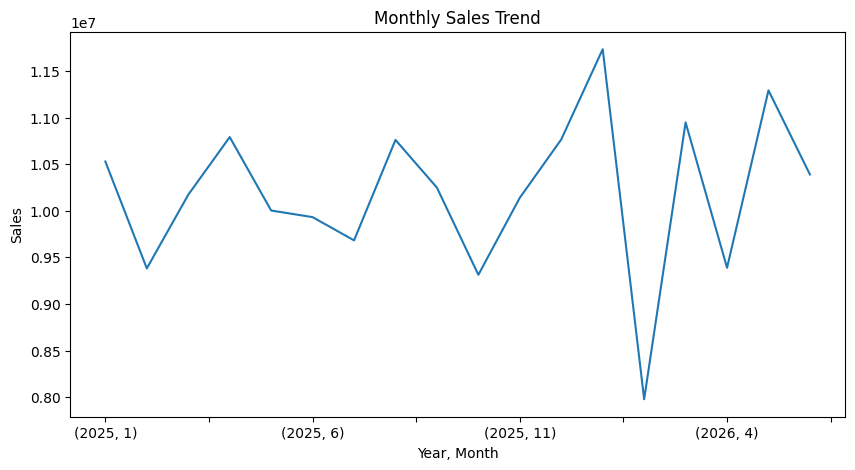

In [318]:
monthly_sales.plot(
    kind="line",
    figsize=(10, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year, Month")
plt.ylabel("Sales")
plt.show()

In [249]:
monthly_sales = df.groupby(["Year", "Month"])["Sales"].sum()

print(monthly_sales)

Year  Month
2025  1        10528830
      2         9381670
      3        10172635
      4        10791815
      5        10003200
      6         9932095
      7         9682640
      8        10761300
      9        10248785
      10        9313150
      11       10140400
      12       10766540
2026  1        11735110
      2         7976940
      3        10949220
      4         9388465
      5        11293215
      6        10390170
Name: Sales, dtype: int64


In [250]:
highest_sales_month = monthly_sales.idxmax()
highest_month_sales = monthly_sales.max()

print("Highest Sales Month:", highest_sales_month)
print("Sales:", highest_month_sales)

Highest Sales Month: (np.int32(2026), np.int32(1))
Sales: 11735110


In [251]:
lowest_sales_month = monthly_sales.idxmin()
lowest_month_sales = monthly_sales.min()

print("Lowest Sales Month:", lowest_sales_month)
print("Sales:", lowest_month_sales)

Lowest Sales Month: (np.int32(2026), np.int32(2))
Sales: 7976940


In [252]:
monthly_growth = monthly_sales.pct_change() * 100

print(monthly_growth)

Year  Month
2025  1              NaN
      2       -10.895418
      3         8.430962
      4         6.086722
      5        -7.307529
      6        -0.710823
      7        -2.511605
      8        11.140144
      9        -4.762575
      10       -9.129228
      11        8.882601
      12        6.174707
2026  1         8.996112
      2       -32.025009
      3        37.260905
      4       -14.254486
      5        20.288194
      6        -7.996350
Name: Sales, dtype: float64


In [253]:
highest_growth_month = monthly_growth.idxmax()
highest_growth = monthly_growth.max()

print("Highest Growth Month:", highest_growth_month)
print("Growth:", highest_growth)

Highest Growth Month: (np.int32(2026), np.int32(3))
Growth: 37.26090455738667


In [254]:
lowest_growth_month = monthly_growth.idxmin()
lowest_growth = monthly_growth.min()

print("Lowest Growth Month:", lowest_growth_month)
print("Growth:", lowest_growth)

Lowest Growth Month: (np.int32(2026), np.int32(2))
Growth: -32.02500871316929


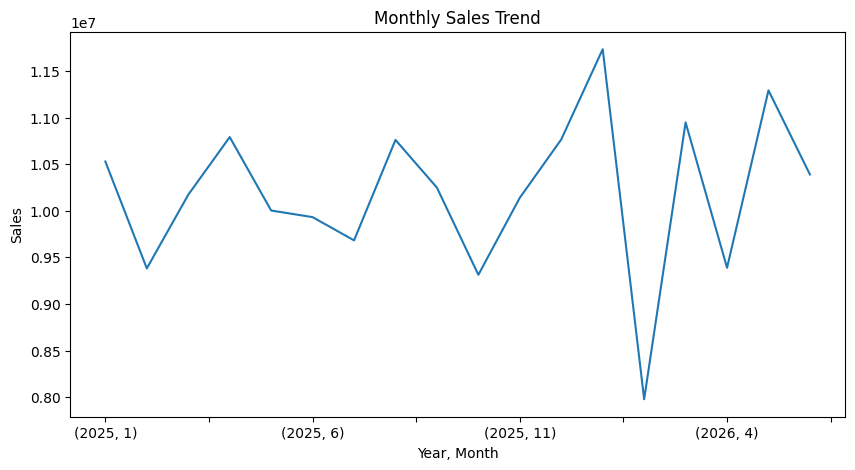

In [255]:
monthly_sales.plot(kind="line", figsize=(10,5))

plt.title("Monthly Sales Trend")
plt.xlabel("Year, Month")
plt.ylabel("Sales")
plt.show()

In [256]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit.sort_values(ascending=False))

Category
Electronics        8034740.50
Furniture          2857965.21
Fashion            2578856.11
Home Appliances    1482053.80
Accessories         651258.07
Name: Profit, dtype: float64


In [257]:
category_analysis = df.groupby("Category")[["Sales", "Profit"]].sum()

category_analysis["Profit_Margin"] = (
    category_analysis["Profit"] / category_analysis["Sales"]
) * 100

print(category_analysis)

                     Sales      Profit  Profit_Margin
Category                                             
Accessories        3122820   651258.07      20.854807
Electronics      136788575  8034740.50       5.873839
Fashion           10006080  2578856.11      25.772891
Furniture         20881375  2857965.21      13.686672
Home Appliances   12657330  1482053.80      11.709056


In [258]:
highest_margin_category = category_analysis["Profit_Margin"].idxmax()
highest_margin = category_analysis["Profit_Margin"].max()

print("Highest Profit Margin Category:", highest_margin_category)
print("Profit Margin:", highest_margin)

Highest Profit Margin Category: Fashion
Profit Margin: 25.772891182161246


In [259]:
lowest_margin_category = category_analysis["Profit_Margin"].idxmin()
lowest_margin = category_analysis["Profit_Margin"].min()

print("Lowest Profit Margin Category:", lowest_margin_category)
print("Profit Margin:", lowest_margin)

Lowest Profit Margin Category: Electronics
Profit Margin: 5.873838878722145


In [260]:
product_analysis = df.groupby("Product")[["Sales", "Profit"]].sum()

product_analysis["Profit_Margin"] = (
    product_analysis["Profit"] / product_analysis["Sales"]
) * 100

print(product_analysis.sort_values("Profit_Margin", ascending=False))

                  Sales      Profit  Profit_Margin
Product                                           
Shoes           5419360  1400567.94      25.843789
T-Shirt         1736460   446485.62      25.712405
Jacket          2850260   731802.55      25.674940
Backpack        3122820   651258.07      20.854807
Office Chair   10515775  1449325.44      13.782393
Desk           10365600  1408639.77      13.589563
Mixer Grinder   4480980   528210.82      11.787841
Coffee Maker    8176350   953842.98      11.665878
Laptop         75598250  4513163.72       5.969931
Smartwatch      8741425   519605.28       5.944171
Headphones      5029500   296874.67       5.902668
Smartphone     47419400  2705096.83       5.704621


In [261]:
low_margin_products = product_analysis[
    product_analysis["Profit_Margin"] < 10
]

print(low_margin_products)

               Sales      Profit  Profit_Margin
Product                                        
Headphones   5029500   296874.67       5.902668
Laptop      75598250  4513163.72       5.969931
Smartphone  47419400  2705096.83       5.704621
Smartwatch   8741425   519605.28       5.944171


In [262]:
loss_orders = df[df["Profit"] < 0]

loss_by_region = loss_orders.groupby("Region")["Order_ID"].count()

print(loss_by_region.sort_values(ascending=False))

Region
West       81
South      53
North      44
Central    37
East       34
Name: Order_ID, dtype: int64


In [263]:
loss_by_product = loss_orders.groupby("Product")["Order_ID"].count()

print(loss_by_product.sort_values(ascending=False))

Product
Smartphone    72
Headphones    71
Smartwatch    56
Laptop        50
Name: Order_ID, dtype: int64


In [264]:
highest_profit_product = product_analysis["Profit"].idxmax()
highest_product_profit = product_analysis["Profit"].max()

print("Highest Profit Product:", highest_profit_product)
print("Profit:", highest_product_profit)

Highest Profit Product: Laptop
Profit: 4513163.72


In [265]:
lowest_profit_product = product_analysis["Profit"].idxmin()
lowest_product_profit = product_analysis["Profit"].min()

print("Lowest Profit Product:", lowest_profit_product)
print("Profit:", lowest_product_profit)

Lowest Profit Product: Headphones
Profit: 296874.67


In [266]:
top_profit_products = (
    product_analysis["Profit"]
    .sort_values(ascending=False)
    .head(3)
)

print(top_profit_products)

Product
Laptop          4513163.72
Smartphone      2705096.83
Office Chair    1449325.44
Name: Profit, dtype: float64


## 9. Customer Analysis

In this section, we will analyze customer sales and order activity to identify high-value customers.

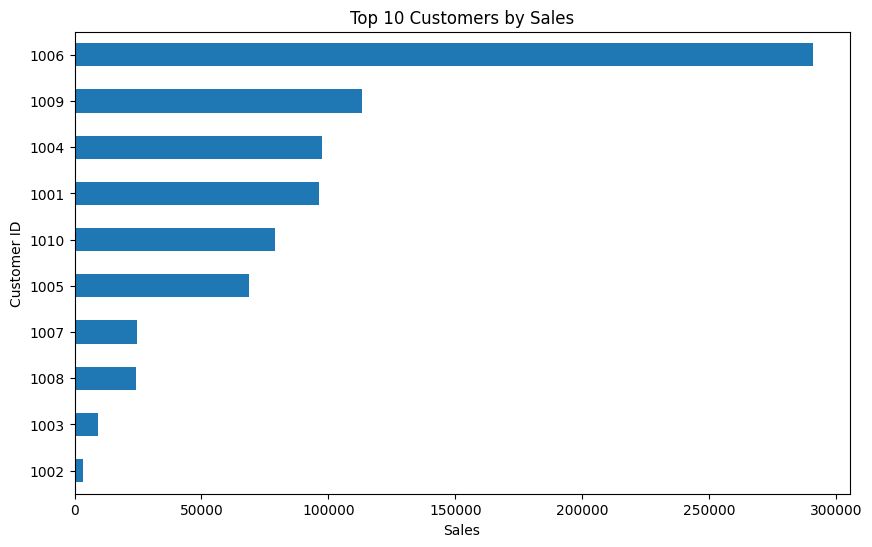

In [319]:
customer_sales.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Sales")
plt.ylabel("Customer ID")
plt.show()

In [267]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum()

top_10_customers = customer_sales.sort_values(
    ascending=False
).head(10)

print(top_10_customers)

Customer_ID
2324    670625
1784    571675
1551    539500
1460    420175
1277    418930
2980    418600
1412    414870
2977    414640
1992    412060
1606    404935
Name: Sales, dtype: int64


In [268]:
customer_profit = df.groupby("Customer_ID")["Profit"].sum()

top_profit_customers = (
    customer_profit
    .sort_values(ascending=False)
    .head(5)
)

print(top_profit_customers)

Customer_ID
1992    54608.24
2324    50982.77
1784    46418.42
2173    45206.05
2390    42863.64
Name: Profit, dtype: float64


In [269]:
customer_orders = df.groupby("Customer_ID")["Order_ID"].count()

top_order_customers = (
    customer_orders
    .sort_values(ascending=False)
    .head(5)
)

print(top_order_customers)

Customer_ID
1596    12
2579    12
3238    11
2134    11
2287    11
Name: Order_ID, dtype: int64


In [270]:
customer_aov = df.groupby("Customer_ID")["Sales"].mean()

top_aov_customers = (
    customer_aov
    .sort_values(ascending=False)
    .head(5)
)

print(top_aov_customers)

Customer_ID
1551    269750.0
2336    221000.0
2717    195000.0
2159    175500.0
2997    175500.0
Name: Sales, dtype: float64


In [271]:
unique_customers = df["Customer_ID"].nunique()

print("Unique Customers:", unique_customers)

Unique Customers: 2450


In [272]:
customers_more_than_5 = customer_orders[customer_orders > 5]

print("Customers with more than 5 orders:", len(customers_more_than_5))

Customers with more than 5 orders: 530


In [273]:
average_customer_sales = customer_sales.mean()

print("Average Sales per Customer:", average_customer_sales)

Average Sales per Customer: 74880.07346938776


In [274]:
customer_summary = df.groupby("Customer_ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count")
)

print(customer_summary.head())

             Total_Sales  Total_Orders
Customer_ID                           
1001               96400             7
1002                3350             2
1003                9340             3
1004               97590             4
1005               68790             6


In [275]:
top_customers = (
    customer_summary[
        customer_summary["Total_Orders"] >= 5
    ]
    .sort_values("Total_Sales", ascending=False)
    .head(5)
)

print(top_customers)

             Total_Sales  Total_Orders
Customer_ID                           
2324              670625             9
1784              571675             6
1460              420175             5
1277              418930             6
2980              418600             6


In [276]:
customer_profit_summary = df.groupby("Customer_ID").agg(
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count")
)

print(customer_profit_summary.head())

             Total_Profit  Total_Orders
Customer_ID                            
1001             10538.08             7
1002               182.21             2
1003              1502.26             3
1004             11795.19             4
1005              5446.23             6


In [277]:
top_profit_customers = (
    customer_profit_summary[
        customer_profit_summary["Total_Orders"] >= 5
    ]
    .sort_values("Total_Profit", ascending=False)
    .head(5)
)

print(top_profit_customers)

             Total_Profit  Total_Orders
Customer_ID                            
2324             50982.77             9
1784             46418.42             6
2173             45206.05             6
2390             42863.64             5
1606             41391.99             9


In [278]:
region_profit = df.groupby("Region").agg(
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "count")
)

region_profit["Avg_Profit_Per_Order"] = (
    region_profit["Total_Profit"] / region_profit["Total_Orders"]
)

print(region_profit)

         Total_Profit  Total_Orders  Avg_Profit_Per_Order
Region                                                   
Central    2249260.34          1451           1550.144962
East       2411463.87          1483           1626.071389
North      3101280.57          1948           1592.033147
South      3486526.56          2242           1555.096592
West       4356342.35          2876           1514.722653


In [279]:
highest_avg_profit_region = region_profit["Avg_Profit_Per_Order"].idxmax()

print(highest_avg_profit_region)

East


In [280]:
region_profit.sort_values("Total_Profit", ascending=False).head(3)

,Total_Profit,Total_Orders,Avg_Profit_Per_Order
Region,,,
West,4356342.35,2876,1514.722653
South,3486526.56,2242,1555.096592
North,3101280.57,1948,1592.033147


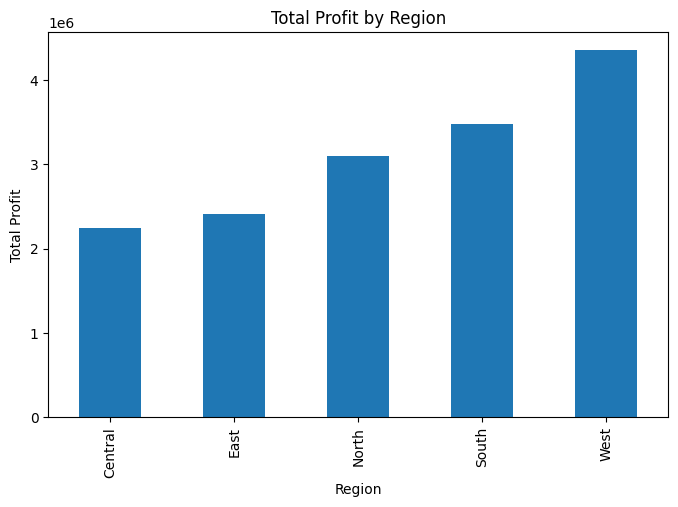

In [281]:
region_profit["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.show()

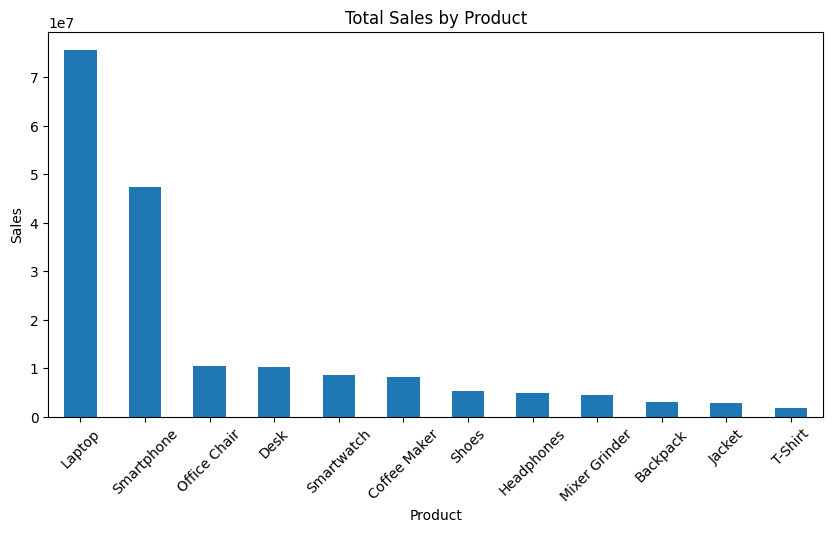

In [282]:
product_sales = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

product_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

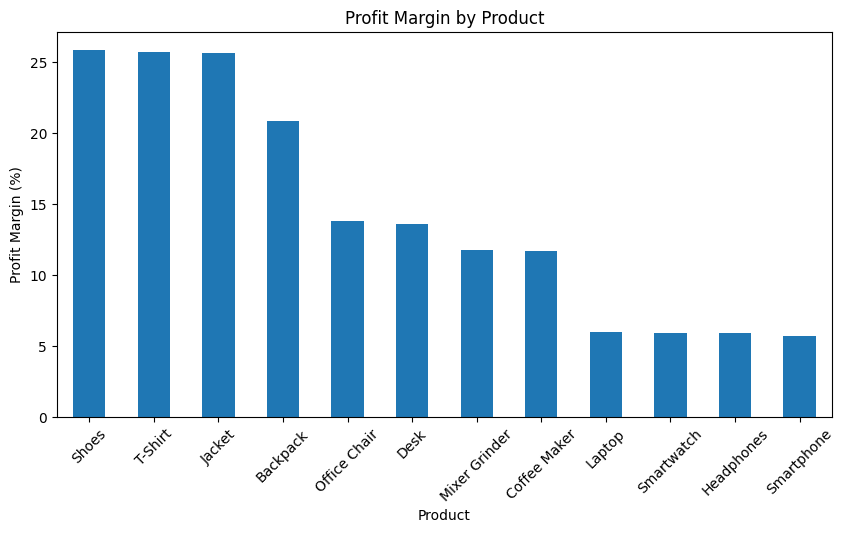

In [283]:
product_analysis["Profit_Margin"].sort_values(ascending=False).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Profit Margin by Product")
plt.xlabel("Product")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.show()

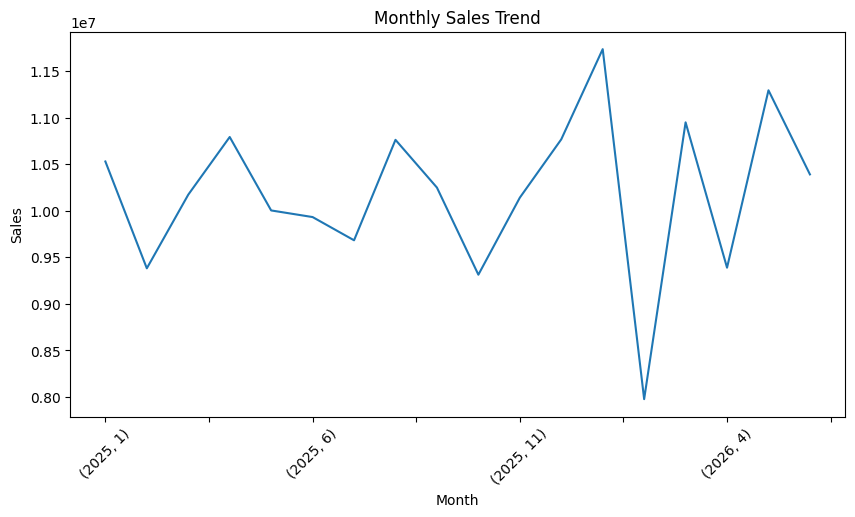

In [284]:
monthly_sales.plot(
    kind="line",
    figsize=(10, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

In [285]:
print("Highest Sales Month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest Sales Month:
(np.int32(2026), np.int32(1)) 11735110

Lowest Sales Month:
(np.int32(2026), np.int32(2)) 7976940


## 10. Payment Mode Analysis

In this section, we will analyze customer payment preferences and sales generated through different payment modes.

In [286]:
payment_counts = df["Payment_Mode"].value_counts()

print(payment_counts)

Payment_Mode
Upi                 3531
Credit Card         2416
Debit Card          1771
Net Banking         1271
Cash On Delivery    1011
Name: count, dtype: int64


In [287]:
payment_sales = df.groupby("Payment_Mode")["Sales"].sum().sort_values(ascending=False)

print(payment_sales)

Payment_Mode
Upi                 63291500
Credit Card         46555055
Debit Card          30310795
Net Banking         25041190
Cash On Delivery    18257640
Name: Sales, dtype: int64


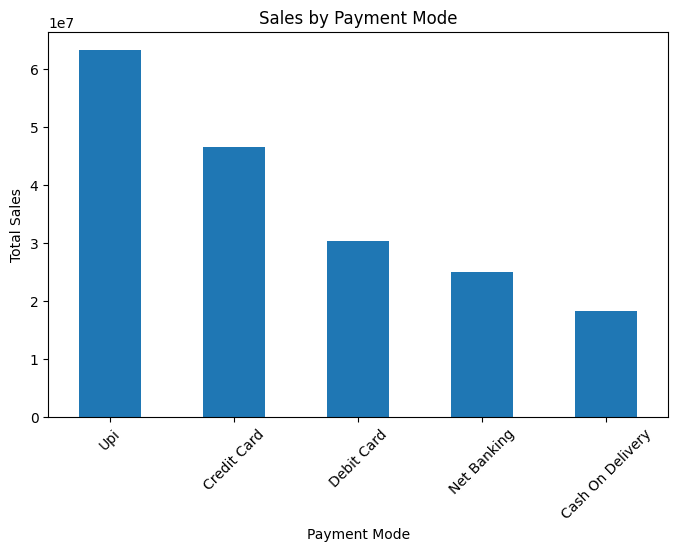

In [288]:
payment_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sales by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

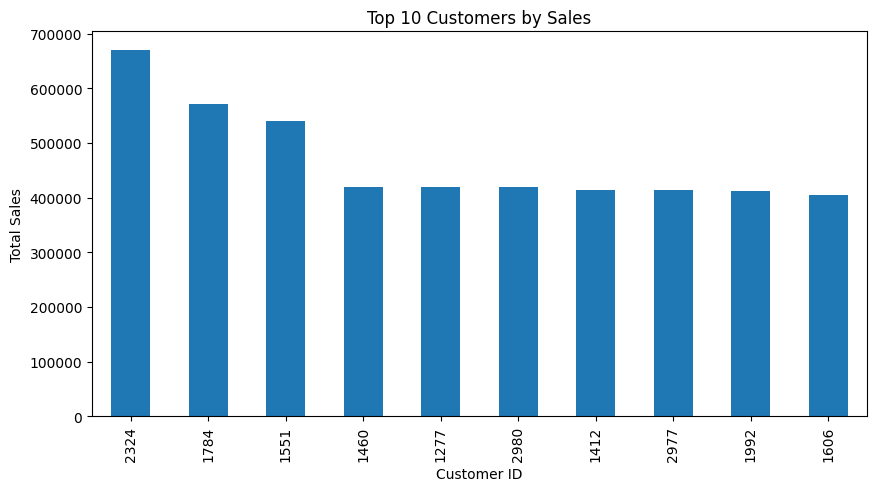

In [289]:
top_10_customers = (
    df.groupby("Customer_ID")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_10_customers.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Customer ID")
plt.ylabel("Total Sales")
plt.show()

In [290]:
customer_analysis = df.groupby("Customer_ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order_ID", "count")
)

top_10_customers = (
    customer_analysis
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

print(top_10_customers)

             Total_Sales  Total_Orders
Customer_ID                           
2324              670625             9
1784              571675             6
1551              539500             2
1460              420175             5
1277              418930             6
2980              418600             6
1412              414870             4
2977              414640             7
1992              412060             3
1606              404935             9


In [291]:
customer_analysis["AOV"] = (
    customer_analysis["Total_Sales"] /
    customer_analysis["Total_Orders"]
)

print(customer_analysis.head())

             Total_Sales  Total_Orders           AOV
Customer_ID                                         
1001               96400             7  13771.428571
1002                3350             2   1675.000000
1003                9340             3   3113.333333
1004               97590             4  24397.500000
1005               68790             6  11465.000000


In [292]:
top_aov_customers = (
    customer_analysis
    .sort_values("AOV", ascending=False)
    .head(5)
)

print(top_aov_customers)

             Total_Sales  Total_Orders       AOV
Customer_ID                                     
1551              539500             2  269750.0
2336              221000             1  221000.0
2717              195000             1  195000.0
2159              175500             1  175500.0
2997              175500             1  175500.0


In [293]:
top_aov_3_orders = (
    customer_analysis[
        customer_analysis["Total_Orders"] >= 3
    ]
    .sort_values("AOV", ascending=False)
    .head(5)
)

print(top_aov_3_orders)

             Total_Sales  Total_Orders            AOV
Customer_ID                                          
1992              412060             3  137353.333333
2895              321535             3  107178.333333
1412              414870             4  103717.500000
3188              299350             3   99783.333333
1149              294600             3   98200.000000


In [294]:
product_order_count = df["Product"].value_counts()

print(product_order_count)

Product
Headphones       1168
T-Shirt          1119
Backpack         1011
Shoes             980
Smartphone        970
Smartwatch        904
Coffee Maker      738
Laptop            704
Office Chair      700
Mixer Grinder     612
Jacket            590
Desk              504
Name: count, dtype: int64


In [295]:
product_avg_sales = df.groupby("Product")["Sales"].mean().sort_values(
    ascending=False
)

print(product_avg_sales)

Product
Laptop           107383.877841
Smartphone        48885.979381
Desk              20566.666667
Office Chair      15022.535714
Coffee Maker      11079.065041
Smartwatch         9669.717920
Mixer Grinder      7321.862745
Shoes              5529.959184
Jacket             4830.949153
Headphones         4306.078767
Backpack           3088.842730
T-Shirt            1551.796247
Name: Sales, dtype: float64


In [296]:
product_avg_sales.head(3)

,Sales
Product,
Laptop,107383.877841
Smartphone,48885.979381
Desk,20566.666667


In [297]:
product_analysis.sort_values(
    "Sales",
    ascending=False
)

,Sales,Profit,Profit_Margin
Product,,,
Laptop,75598250,4513163.72,5.969931
Smartphone,47419400,2705096.83,5.704621
Office Chair,10515775,1449325.44,13.782393
Desk,10365600,1408639.77,13.589563
Smartwatch,8741425,519605.28,5.944171
Coffee Maker,8176350,953842.98,11.665878
Shoes,5419360,1400567.94,25.843789
Headphones,5029500,296874.67,5.902668
Mixer Grinder,4480980,528210.82,11.787841


In [298]:
low_margin_products = product_analysis[
    product_analysis["Profit_Margin"] < 10
]

print(low_margin_products)

               Sales      Profit  Profit_Margin
Product                                        
Headphones   5029500   296874.67       5.902668
Laptop      75598250  4513163.72       5.969931
Smartphone  47419400  2705096.83       5.704621
Smartwatch   8741425   519605.28       5.944171


In [299]:
top_margin_products = (
    product_analysis
    .sort_values("Profit_Margin", ascending=False)
    .head(3)
)

print(top_margin_products)

           Sales      Profit  Profit_Margin
Product                                    
Shoes    5419360  1400567.94      25.843789
T-Shirt  1736460   446485.62      25.712405
Jacket   2850260   731802.55      25.674940


## 11. Loss & Discount Analysis

In this section, we will analyze loss-making orders and examine their relationship with discount levels.

In [300]:
loss_orders = df[df["Profit"] < 0]

loss_by_product = loss_orders["Product"].value_counts()

print(loss_by_product)

Product
Smartphone    72
Headphones    71
Smartwatch    56
Laptop        50
Name: count, dtype: int64


In [301]:
loss_discount = df[df["Profit"] < 0]["Discount"].mean()
profit_discount = df[df["Profit"] >= 0]["Discount"].mean()

print("Average Discount on Loss Orders:", loss_discount)
print("Average Discount on Profitable Orders:", profit_discount)

Average Discount on Loss Orders: 0.22630522088353414
Average Discount on Profitable Orders: 0.09654394421085018


In [302]:
loss_discount_count = (
    loss_orders["Discount"]
    .value_counts()
    .sort_index()
)

print(loss_discount_count)

Discount
0.15     14
0.20     90
0.25    145
Name: count, dtype: int64


In [303]:
loss_25 = loss_orders[loss_orders["Discount"] == 0.25]

loss_25_by_product = loss_25["Product"].value_counts()

print(loss_25_by_product)

Product
Smartphone    46
Headphones    39
Laptop        30
Smartwatch    30
Name: count, dtype: int64


In [304]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
average_order_value = df["Sales"].mean()

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", average_order_value)

Total Sales: 183456180
Total Profit: 15604873.690000001
Total Orders: 10000
Total Customers: 2450
Average Order Value: 18345.618


In [305]:
overall_profit_margin = (total_profit / total_sales) * 100

print("Overall Profit Margin:", overall_profit_margin)

Overall Profit Margin: 8.50604961359165


In [306]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Average Order Value",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        average_order_value,
        overall_profit_margin
    ]
})

print(kpi_summary)

                   KPI         Value
0          Total Sales  1.834562e+08
1         Total Profit  1.560487e+07
2         Total Orders  1.000000e+04
3      Total Customers  2.450000e+03
4  Average Order Value  1.834562e+04
5        Profit Margin  8.506050e+00


In [307]:
kpi_summary["Value"] = kpi_summary["Value"].round(2)

print(kpi_summary.to_string(index=False))

                KPI        Value
        Total Sales 183456180.00
       Total Profit  15604873.69
       Total Orders     10000.00
    Total Customers      2450.00
Average Order Value     18345.62
      Profit Margin         8.51


## 12. Business Insights & Recommendations

### 1. Smartphone Profitability
Smartphones have the highest number of loss-making orders at the 25% discount level and have a low overall profit margin of 5.70%.
Recommendation: Review high-discount promotions for smartphones to reduce potential losses.

### 2. Regional Performance
The West region has the highest sales and profit.
Recommendation: Maintain the successful strategy in the West region and explore further growth opportunities.

### 3. Product Profitability
Shoes have the highest profit margin at 25.84%.
Recommendation: Consider increasing inventory and focusing more on Shoes to take advantage of their high profitability.

### 4. Monthly Sales Performance
February 2026 had the lowest monthly sales.
Recommendation: Investigate the reasons for the sales decline, such as changes in demand, discounts, product availability, or marketing activities.

### 5. Laptop Profitability
Laptops generate the highest sales but have a relatively low profit margin of 5.97%.
Recommendation: Review Laptop pricing, costs, and discounts to improve profitability without significantly affecting demand.

## 13. Conclusion

This project analyzed 10,000 e-commerce orders using Python and Pandas.

The analysis focused on sales, profit, products, categories, regions, customers, payment modes, monthly trends, and loss-making orders.

Key findings include:
- Laptop generated the highest sales.
- Electronics was the highest-performing category by sales and profit.
- West was the best-performing region in terms of sales and profit.
- Shoes had the highest profit margin.
- February 2026 had the lowest monthly sales.
- Smartphones had the highest number of loss-making orders at the 25% discount level.

The analysis helped identify areas for improving profitability, reviewing discount strategies, and focusing on high-performing products and regions.